In [17]:
import pandas as pd
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
# Base directory
base_path = Path('/Users/liuq13/SPCD_data/beh_processed')

In [ ]:
# Store run-level accuracy across subjects
all_run_acc = []

# Loop through each subject folder
for subj_folder in sorted(base_path.glob('sub-*')):
    file_path = subj_folder / 'odor_pred_dat.csv'
    if not file_path.exists():
        continue

    df = pd.read_csv(file_path)
    
    # Ensure numeric
    df['Run'] = pd.to_numeric(df['Run'], errors='coerce')
    df['acc'] = pd.to_numeric(df['acc'], errors='coerce')
    
    # Drop invalid
    df = df.dropna(subset=['Run', 'acc'])

    # Compute mean acc per run
    acc_by_run = df.groupby('Run')['acc'].mean().reset_index()

    # Add subject ID
    acc_by_run['subject'] = subj_folder.name

    # Reorder columns
    acc_by_run = acc_by_run[['subject', 'Run', 'acc']]
    acc_by_run.rename(columns={'acc': 'mean_acc'}, inplace=True)

    all_run_acc.append(acc_by_run)

# Combine all subjects
result_df = pd.concat(all_run_acc, ignore_index=True)

# Display or save
print(result_df)

    subject  Run  mean_acc
0    sub-01  1.0  0.888889
1    sub-01  2.0  1.000000
2    sub-01  3.0  1.000000
3    sub-02  1.0  0.750000
4    sub-02  2.0  0.916667
..      ...  ...       ...
97   sub-40  2.0  0.944444
98   sub-40  3.0  0.888889
99   sub-41  1.0  0.666667
100  sub-41  2.0  0.888889
101  sub-41  3.0  0.972222

[102 rows x 3 columns]


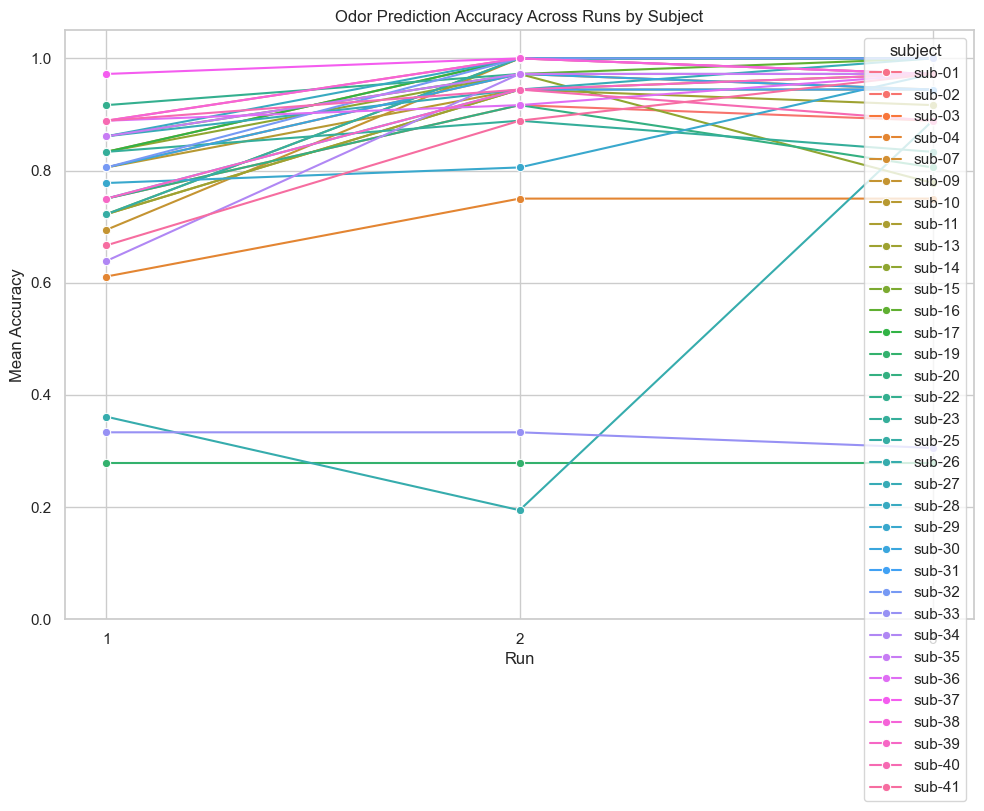

In [4]:


# Set plot style
sns.set(style='whitegrid')

# Plot
plt.figure(figsize=(10, 8))
sns.lineplot(data=result_df, x='Run', y='mean_acc', hue='subject', marker='o')

plt.title('Odor Prediction Accuracy Across Runs by Subject')
plt.xlabel('Run')
plt.ylabel('Mean Accuracy')
plt.ylim(0, 1.05)
plt.xticks(sorted(df['Run'].unique()))
plt.tight_layout()
plt.show()

In [19]:
# Collect pre/post data
pre_records = []
post_records = []

# Loop through subjects
for subj_folder in sorted(base_path.glob('sub-*')):
    subj = subj_folder.name

    # --- Pre-meal ---
    pre_path = subj_folder / 'pre_meal_dat.csv'
    if pre_path.exists():
        df_pre = pd.read_csv(pre_path)
        df_pre = df_pre.dropna(subset=['choice_class', 'acc'])
        pre = df_pre.groupby('choice_class')['acc'].mean().reset_index()
        pre['subject'] = subj
        pre['phase'] = 'pre'
        pre_records.append(pre)

    # --- Post-meal ---
    post_path = subj_folder / 'post_meal_dat.csv'
    if post_path.exists():
        df_post = pd.read_csv(post_path)
        df_post = df_post.dropna(subset=['choice_class', 'acc'])
        post = df_post.groupby('choice_class')['acc'].mean().reset_index()
        post['subject'] = subj
        post['phase'] = 'post'
        post_records.append(post)

# Combine all
df_all = pd.concat(pre_records + post_records, ignore_index=True)

# Pivot to wide format (pre, post)
pivoted = df_all.pivot_table(index=['subject', 'choice_class'], columns='phase', values='acc').reset_index()
pivoted['change'] = pivoted['post'] - pivoted['pre']

# Save to CSV
pivoted.to_csv(base_path / 'choice_class_accuracy_change_pre_post.csv', index=False)
print("✅ Saved: choice_class_accuracy_change_pre_post.csv")


✅ Saved: choice_class_accuracy_change_pre_post.csv


/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_6622/54916231.py:8: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(data=df_long, x='choice_class', y='mean_acc', hue='phase',


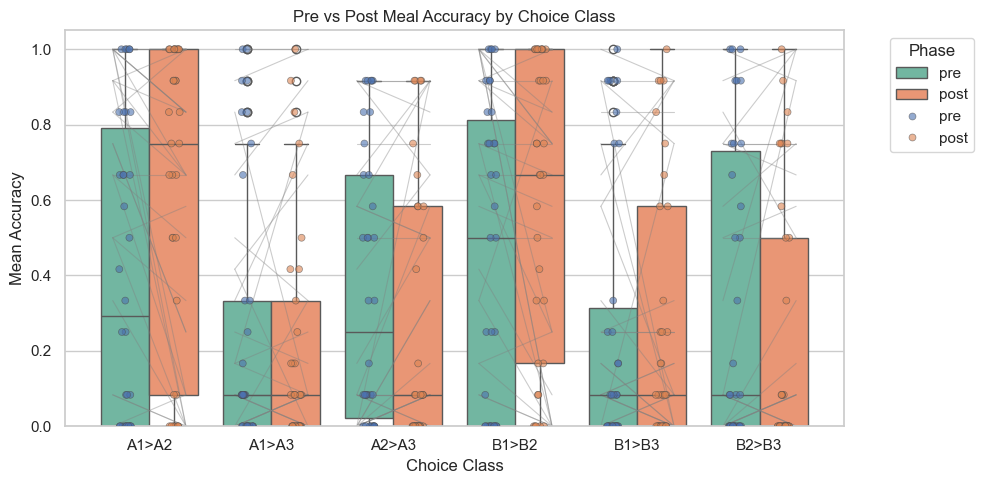

In [25]:
# Make numeric labels for choice_class
unique_classes = sorted(df_long['choice_class'].unique())
class_to_num = {label: i for i, label in enumerate(unique_classes)}

# Plot
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_long, x='choice_class', y='mean_acc', hue='phase', palette='Set2')
sns.stripplot(data=df_long, x='choice_class', y='mean_acc', hue='phase',
              dodge=True, jitter=True, alpha=0.6, linewidth=0.5, edgecolor='gray')

# Draw connecting lines
for (subj, cls), group in df_long.groupby(['subject', 'choice_class']):
    if group.shape[0] == 2:
        base_x = class_to_num[cls]
        x_vals = [base_x - 0.3, base_x + 0.3]  # Pre and post offset
        y_vals = group.sort_values('phase')['mean_acc'].tolist()
        plt.plot(x_vals, y_vals, color='gray', alpha=0.4, linewidth=0.8)

plt.title('Pre vs Post Meal Accuracy by Choice Class')
plt.xlabel('Choice Class')
plt.ylabel('Mean Accuracy')
plt.ylim(0, 1.05)
plt.legend(title='Phase', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [ ]:
from scipy.stats import ttest_rel
import pandas as pd

# Load data (or reuse pivoted if already in memory)
base_path = Path('/Users/liuq13/SPCD_data/beh_processed')
pivoted = pd.read_csv(base_path / 'choice_class_accuracy_change_pre_post.csv')

In [27]:
pivoted

,subject,choice_class,post,pre,change
0,sub-01,A1>A2,1.000000,0.083333,0.916667
1,sub-01,A1>A3,0.166667,0.083333,0.083333
2,sub-01,A2>A3,0.000000,0.083333,-0.083333
3,sub-01,B1>B2,1.000000,0.250000,0.750000
4,sub-01,B1>B3,0.000000,0.000000,0.000000
...,...,...,...,...,...
199,sub-41,A1>A3,0.000000,0.083333,-0.083333
200,sub-41,A2>A3,0.083333,0.000000,0.083333
201,sub-41,B1>B2,0.750000,0.750000,0.000000
202,sub-41,B1>B3,0.083333,0.083333,0.000000


In [28]:
from scipy.stats import ttest_rel
import pandas as pd

pivoted = pd.read_csv('/Users/liuq13/SPCD_data/beh_processed/choice_class_accuracy_change_pre_post.csv')

test_results = []

for cls, group in pivoted.groupby('choice_class'):
    group_clean = group.dropna(subset=['pre', 'post'])
    if group_clean.shape[0] < 2:
        continue

    pre = group_clean['pre']
    post = group_clean['post']
    t_stat, p_val = ttest_rel(pre, post)

    test_results.append({
        'choice_class': cls,
        'n': group_clean.shape[0],
        't_stat': t_stat,
        'p_val': p_val,
        'significance': (
            '***' if p_val < 0.001 else
            '**' if p_val < 0.01 else
            '*' if p_val < 0.05 else
            'ns'
        )
    })

stat_df = pd.DataFrame(test_results).sort_values('p_val')
stat_df.to_csv('/Users/liuq13/SPCD_data/beh_processed/choice_class_ttest_results.csv', index=False)
print(stat_df)


  choice_class   n    t_stat     p_val significance
0        A1>A2  33 -3.825551  0.000570          ***
3        B1>B2  33 -2.907402  0.006570           **
2        A2>A3  33  2.459164  0.019517            *
5        B2>B3  33  1.794705  0.082153           ns
4        B1>B3  33 -0.928820  0.359936           ns
1        A1>A3  33  0.569068  0.573283           ns


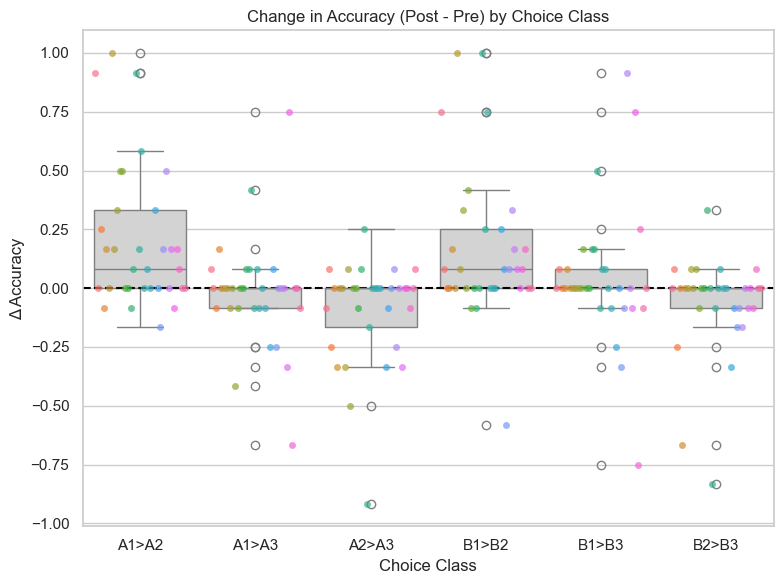

In [24]:
# plot change from pre to post
plt.figure(figsize=(8, 6))
sns.boxplot(data=pivoted, x='choice_class', y='change', color='lightgray')
sns.stripplot(data=pivoted, x='choice_class', y='change', hue='subject', jitter=True, alpha=0.7, dodge=True)

plt.axhline(0, color='black', linestyle='--')
plt.title('Change in Accuracy (Post - Pre) by Choice Class')
plt.xlabel('Choice Class')
plt.ylabel('Δ Accuracy')
plt.legend([],[], frameon=False)  # Hide subject legend for clarity
plt.tight_layout()
plt.show()
